In [38]:
import pandas as pd
import numpy as np 


In [39]:
df=pd.read_csv('insurance.csv')
cdf=df.copy()

In [40]:
cdf.shape

(1338, 7)

In [41]:
cdf.sample(10)

,age,sex,bmi,children,smoker,region,charges
443,59,female,36.520,1,no,southeast,28287.89766
952,30,female,28.405,1,no,northwest,4527.18295
75,57,male,34.010,0,no,northwest,11356.66090
1199,31,female,25.800,2,no,southwest,4934.70500
18,56,male,40.300,0,no,southwest,10602.38500
664,64,female,22.990,0,yes,southeast,27037.91410
576,22,male,26.840,0,no,southeast,1664.99960
752,64,male,37.905,0,no,northwest,14210.53595
1057,45,female,31.790,0,no,southeast,17929.30337
340,24,female,27.600,0,no,southwest,18955.22017


In [42]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [43]:
print("Missing values :",cdf.isna().sum())

Missing values : age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [44]:
df.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [45]:
cdf.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [46]:
cdf=cdf.drop_duplicates(cdf)
cdf.duplicated().sum()

np.int64(0)

In [47]:
text_col=[cdf.select_dtypes(['object','string']).columns.to_list()]
print(text_col)
numeric_col=[cdf.select_dtypes(['int','Int64','float','float64']).columns.to_list()]
print(numeric_col)

[['sex', 'smoker', 'region']]
[['age', 'bmi', 'children', 'charges']]


In [48]:
for col in text_col[0]:
    cdf[col]=cdf[col].str.title()

***Univariate Analysis***

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Number of Smoker Distribution')

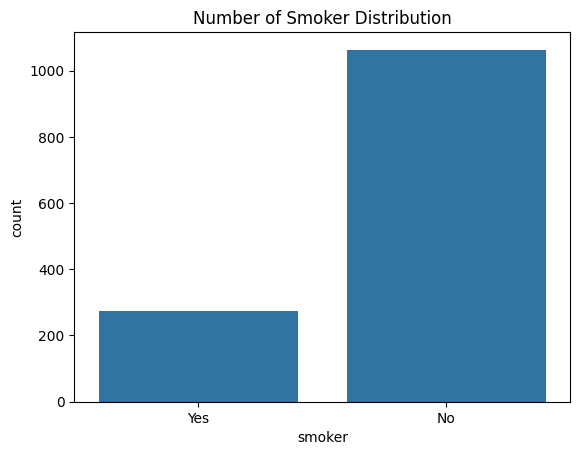

In [50]:
#smoker vs gender 

sns.countplot(data=cdf,x='smoker')
plt.title("Number of Smoker Distribution")

In [51]:
cdf['sex']=cdf.sex.replace({
    'Male':'0',
    'Female':'1'
})

cdf['sex']=cdf.sex.astype(float)

In [52]:
cdf.sex.value_counts()

sex
0.0    675
1.0    662
Name: count, dtype: int64

In [53]:
cdf['smoker']=cdf.smoker.replace({
    'Yes':'0',
    'No':'1'
})
cdf['smoker']=cdf['smoker'].astype('Int64')

In [54]:
cdf.region.value_counts()

region
Southeast    364
Southwest    325
Northwest    324
Northeast    324
Name: count, dtype: int64

In [59]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='first', sparse_output=False)

df_encoder = ohe.fit_transform(cdf[['region']])

encoded_columns = ohe.get_feature_names_out(['region'])

df_encoded = cdf.drop(columns=['region']).join(
    pd.DataFrame(df_encoder, columns=encoded_columns, index=cdf.index)
)

df_encoded.head()

,age,sex,bmi,children,smoker,charges,region_Northwest,region_Southeast,region_Southwest
0,19,1.0,27.900,0,0,16884.92400,0.0,0.0,1.0
1,18,0.0,33.770,1,1,1725.55230,0.0,1.0,0.0
2,28,0.0,33.000,3,1,4449.46200,0.0,1.0,0.0
3,33,0.0,22.705,0,1,21984.47061,1.0,0.0,0.0
4,32,0.0,28.880,0,1,3866.85520,1.0,0.0,0.0


In [57]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   float64
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   Int64  
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: Int64(1), float64(3), int64(2), object(1)
memory usage: 84.9+ KB


In [64]:
X=df_encoded.drop(['charges'],axis=1)
Y=df_encoded['charges']

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
model=LinearRegression()

model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [66]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

y_pred=model.predict(x_test)
print("r2_score :",r2_score(y_test,y_pred))
print("MSE :",mean_squared_error(y_test,y_pred))
print("MAE :",mean_absolute_error(y_test,y_pred))

r2_score : 0.8069287081198014
MSE : 35478020.67523555
MAE : 4177.045561036313
